In [26]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [27]:
thu_muc_goc = Path.cwd()
if not (thu_muc_goc / "data/raw/ratings.dat").exists():
    thu_muc_goc = thu_muc_goc.parent
thu_muc_du_lieu = thu_muc_goc / "data/raw"
ratings = pd.read_csv(
    "../data/raw/ratings.dat",
    sep="::",
    engine="python",
    names=["user_id", "movie_id", "rating", "timestamp"],
    encoding="latin-1"
)

users = pd.read_csv(
    "../data/raw/users.dat",
    sep="::",
    engine="python",
    names=["user_id", "gender", "age", "occupation", "zip_code"],
    encoding="latin-1"
)

movies = pd.read_csv(
    "../data/raw/movies.dat",
    sep="::",
    engine="python",
    names=["movie_id", "title", "genres"],
    encoding="latin-1"
)

In [28]:
print("Ratings:", ratings.shape)
print("Users:", users.shape)
print("Movies:", movies.shape)

Ratings: (1000209, 4)
Users: (6040, 5)
Movies: (3883, 3)


In [29]:
display(ratings.head())
display(users.head())
display(movies.head())


,user_id,movie_id,rating,timestamp
0,1,1193,5,978300760
1,1,661,3,978302109
2,1,914,3,978301968
3,1,3408,4,978300275
4,1,2355,5,978824291


,user_id,gender,age,occupation,zip_code
0,1,F,1,10,48067
1,2,M,56,16,70072
2,3,M,25,15,55117
3,4,M,45,7,02460
4,5,M,25,20,55455


,movie_id,title,genres
0,1,Toy Story (1995),Animation|Children's|Comedy
1,2,Jumanji (1995),Adventure|Children's|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama
4,5,Father of the Bride Part II (1995),Comedy


In [30]:
print("Ratings:")
print(ratings.info())

print("\nUsers:")
print(users.info())

print("\nMovies:")
print(movies.info())

Ratings:
<class 'pandas.DataFrame'>
RangeIndex: 1000209 entries, 0 to 1000208
Data columns (total 4 columns):
 #   Column     Non-Null Count    Dtype
---  ------     --------------    -----
 0   user_id    1000209 non-null  int64
 1   movie_id   1000209 non-null  int64
 2   rating     1000209 non-null  int64
 3   timestamp  1000209 non-null  int64
dtypes: int64(4)
memory usage: 30.5 MB
None

Users:
<class 'pandas.DataFrame'>
RangeIndex: 6040 entries, 0 to 6039
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   user_id     6040 non-null   int64
 1   gender      6040 non-null   str  
 2   age         6040 non-null   int64
 3   occupation  6040 non-null   int64
 4   zip_code    6040 non-null   str  
dtypes: int64(3), str(2)
memory usage: 271.8 KB
None

Movies:
<class 'pandas.DataFrame'>
RangeIndex: 3883 entries, 0 to 3882
Data columns (total 3 columns):
 #   Column    Non-Null Count  Dtype
---  ------    --------------  -----

In [31]:
print("Ratings:")
print(ratings.isnull().sum())

print("\nUsers:")
print(users.isnull().sum())

print("\nMovies:")
print(movies.isnull().sum())

Ratings:
user_id      0
movie_id     0
rating       0
timestamp    0
dtype: int64

Users:
user_id       0
gender        0
age           0
occupation    0
zip_code      0
dtype: int64

Movies:
movie_id    0
title       0
genres      0
dtype: int64


In [32]:
print("Ratings trùng lặp:", ratings.duplicated().sum())
print("Users trùng lặp:", users.duplicated().sum())
print("Movies trùng lặp:", movies.duplicated().sum())

Ratings trùng lặp: 0
Users trùng lặp: 0
Movies trùng lặp: 0


### Rating

In [33]:
ratings["user_id"].value_counts()

user_id
4169    2314
1680    1850
4277    1743
1941    1595
1181    1521
        ... 
5533      20
5725      20
5828      20
5904      20
6038      20
Name: count, Length: 6040, dtype: int64

In [34]:
phan_phoi = ratings["rating"].value_counts().sort_index()
print(phan_phoi)

rating
1     56174
2    107557
3    261197
4    348971
5    226310
Name: count, dtype: int64


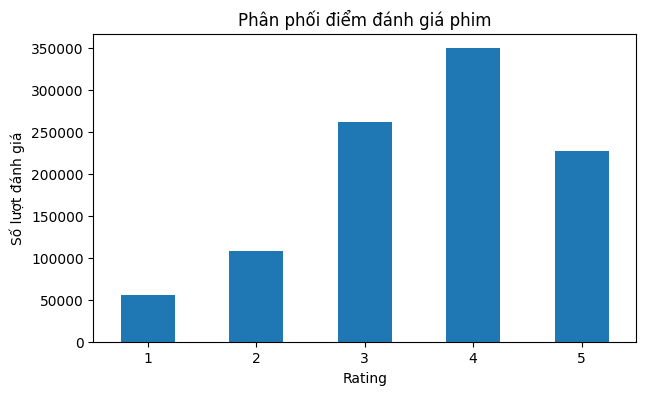

In [35]:
phan_phoi.plot(
    kind="bar",
    figsize=(7, 4)
)

plt.title("Phân phối điểm đánh giá phim")
plt.xlabel("Rating")
plt.ylabel("Số lượt đánh giá")
plt.xticks(rotation=0)
plt.show()

In [36]:
n_users = ratings["user_id"].nunique()
n_movies = ratings["movie_id"].nunique()
n_ratings = len(ratings)

sparsity = (1 - n_ratings / (n_users * n_movies)) * 100

print(f"Độ thưa của ma trận: {sparsity:.2f}%")

Độ thưa của ma trận: 95.53%


In [37]:
print("Số lượt đánh giá trung bình mỗi người dùng:",
      ratings.groupby("user_id")["rating"].count().mean().round(2))

print("Số lượt đánh giá trung bình mỗi phim:",
      ratings.groupby("movie_id")["rating"].count().mean().round(2))

Số lượt đánh giá trung bình mỗi người dùng: 165.6
Số lượt đánh giá trung bình mỗi phim: 269.89


In [38]:
ratings["rating"].describe()

count    1.000209e+06
mean     3.581564e+00
std      1.117102e+00
min      1.000000e+00
25%      3.000000e+00
50%      4.000000e+00
75%      4.000000e+00
max      5.000000e+00
Name: rating, dtype: float64

In [39]:
so_dg_moi_phim = ratings["movie_id"].value_counts()

print("Số phim:", len(so_dg_moi_phim))
print("\nThống kê số lượt đánh giá mỗi phim:")
print(so_dg_moi_phim.describe())

Số phim: 3706

Thống kê số lượt đánh giá mỗi phim:
count    3706.000000
mean      269.889099
std       384.047838
min         1.000000
25%        33.000000
50%       123.500000
75%       350.000000
max      3428.000000
Name: count, dtype: float64


In [40]:
phim_da_danh_gia = set(ratings["movie_id"].unique())
tat_ca_phim = set(movies["movie_id"].unique())

phim_chua_danh_gia = tat_ca_phim - phim_da_danh_gia

print("Số phim chưa có đánh giá:", len(phim_chua_danh_gia))

Số phim chưa có đánh giá: 177


### User

In [41]:
users["gender"].value_counts()

gender
M    4331
F    1709
Name: count, dtype: int64

<Axes: >

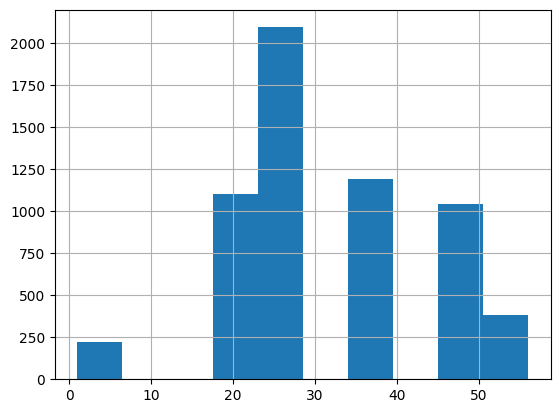

In [42]:
users['age'].hist()

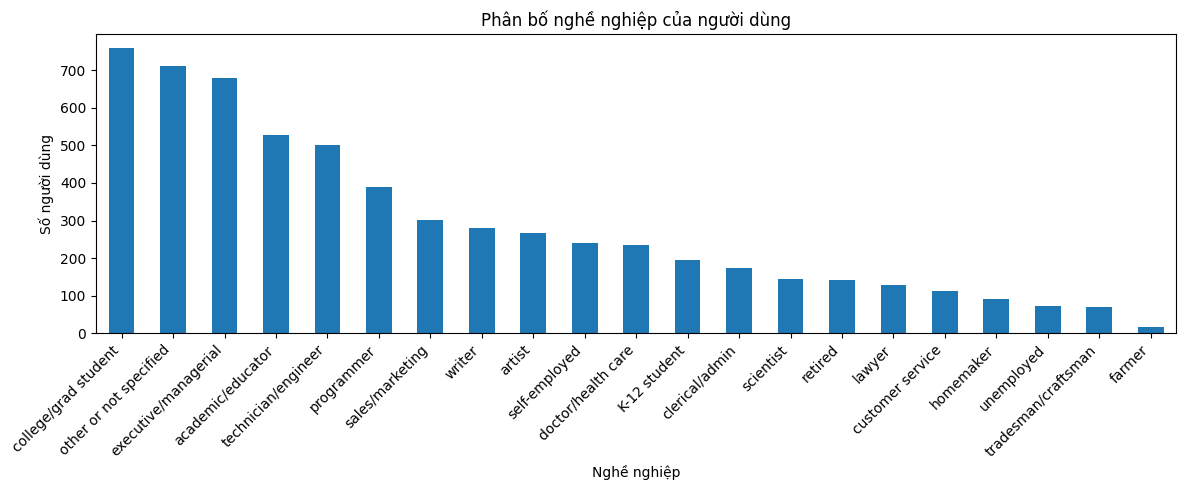

In [43]:
occupation_mapping = {
    0: "other or not specified",
    1: "academic/educator",
    2: "artist",
    3: "clerical/admin",
    4: "college/grad student",
    5: "customer service",
    6: "doctor/health care",
    7: "executive/managerial",
    8: "farmer",
    9: "homemaker",
    10: "K-12 student",
    11: "lawyer",
    12: "programmer",
    13: "retired",
    14: "sales/marketing",
    15: "scientist",
    16: "self-employed",
    17: "technician/engineer",
    18: "tradesman/craftsman",
    19: "unemployed",
    20: "writer",
}
occupation_count = users["occupation"].map(occupation_mapping).value_counts()

occupation_count.plot(kind="bar", figsize=(12, 5))

plt.xlabel("Nghề nghiệp")
plt.ylabel("Số người dùng")
plt.title("Phân bố nghề nghiệp của người dùng")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Movies

In [44]:
movies["num_genres"] = movies["genres"].apply(lambda x: len(x.split("|")))

In [45]:
movies["num_genres"].value_counts().sort_index()

num_genres
1    2025
2    1322
3     421
4     100
5      14
6       1
Name: count, dtype: int64

In [46]:
from collections import defaultdict

dem_the_loai = defaultdict(int)

for the_loai in movies["genres"]:
    for genre in the_loai.split("|"):
        dem_the_loai[genre] += 1

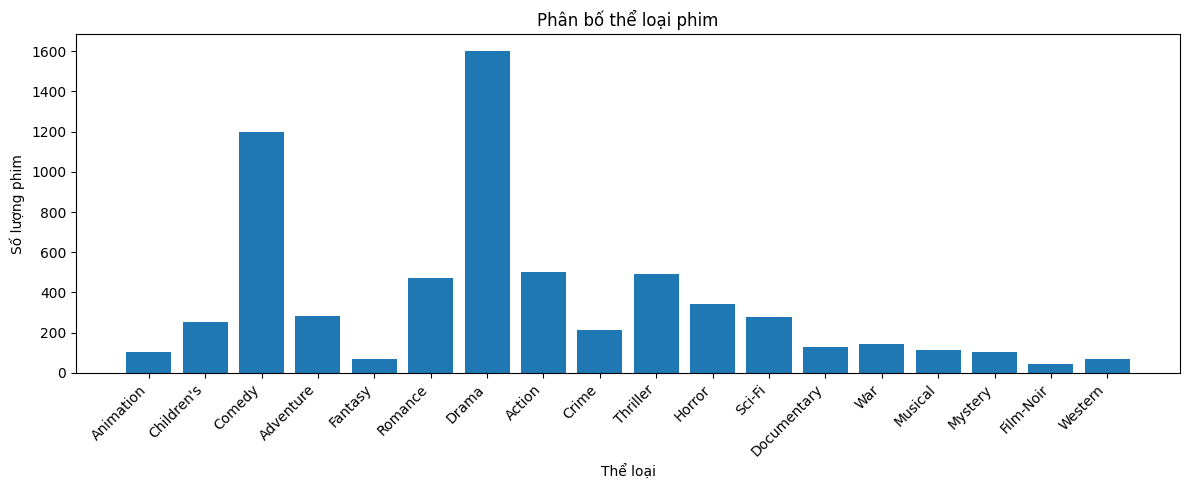

In [47]:
plt.figure(figsize=(12, 5))
plt.bar(dem_the_loai.keys(), dem_the_loai.values())
plt.xticks(rotation=45, ha="right")
plt.xlabel("Thể loại")
plt.ylabel("Số lượng phim")
plt.title("Phân bố thể loại phim")
plt.tight_layout()
plt.show()

In [48]:
print("User không tồn tại:", 
      (~ratings["user_id"].isin(users["user_id"])).sum())

print("Movie không tồn tại:", 
      (~ratings["movie_id"].isin(movies["movie_id"])).sum())

User không tồn tại: 0
Movie không tồn tại: 0


In [49]:
import sys
if str(thu_muc_goc) not in sys.path:
    sys.path.insert(0, str(thu_muc_goc))
from src.du_lieu import chia_du_lieu
train_data, test_data = chia_du_lieu(ratings)

In [50]:
print("Train:", train_data.shape)
print("Test:", test_data.shape)

Train: (800167, 4)
Test: (200042, 4)


In [51]:
print("User chỉ có trong test:",
      len(set(test_data["user_id"]) - set(train_data["user_id"])))

print("Movie chỉ có trong test:",
      len(set(test_data["movie_id"]) - set(train_data["movie_id"])))

User chỉ có trong test: 0
Movie chỉ có trong test: 23


In [52]:
test_only_movies = set(test_data["movie_id"]) - set(train_data["movie_id"])

ratings[ratings["movie_id"].isin(test_only_movies)]["movie_id"].value_counts()

movie_id
3085    2
3381    2
2811    2
826     1
576     1
545     1
814     1
3151    1
2484    1
3321    1
142     1
1815    1
1430    1
2213    1
2217    1
1709    1
3164    1
3315    1
2438    1
3382    1
1843    1
286     1
2845    1
Name: count, dtype: int64

In [53]:
print("Tỷ lệ rating trong Train:")
print(train_data["rating"].value_counts(normalize=True).sort_index().round(4))

print("\nTỷ lệ rating trong Test:")
print(test_data["rating"].value_counts(normalize=True).sort_index().round(4))

Tỷ lệ rating trong Train:
rating
1    0.0560
2    0.1077
3    0.2613
4    0.3491
5    0.2259
Name: proportion, dtype: float64

Tỷ lệ rating trong Test:
rating
1    0.0570
2    0.1068
3    0.2605
4    0.3482
5    0.2275
Name: proportion, dtype: float64


In [54]:
train_data.to_csv("../data/processed/train.csv", index=False)
test_data.to_csv("../data/processed/test.csv", index=False)